# Tugas P2 — Representasi Data & Pra-pemrosesan
**MK. Pembelajaran Mesin** · Algoritma: **K-Nearest Neighbors (KNN)**

## Kasus: Klasifikasi Tingkat Obesitas dari Kebiasaan Makan & Kondisi Fisik

**Masalah.** Obesitas adalah masalah kesehatan yang terus meningkat. Deteksi dini tingkat berat badan seseorang
dari kebiasaan sehari-harinya (pola makan, aktivitas fisik, transportasi, dll.) dapat membantu tindakan pencegahan.

**Tujuan.** Memprediksi `Obesity_Level` (7 kelas) memakai KNN, dengan fokus pada pra-pemrosesan data:
tipe kolom, missing values, duplikasi, kategori, normalisasi/standarisasi, outlier (IQR), class imbalance, dan **data leakage**.

**Dataset.** *Estimation of obesity levels based on eating habits and physical condition* (UCI Machine Learning Repository / Kaggle).
File: `ObesityDataSet_raw_and_data_sinthetic.csv` — 2.111 baris, 16 fitur + 1 target.

> Link data: https://www.kaggle.com/datasets/fatemehmehrparvar/obesity-levels

**Alur notebook**
1. Setup library
2. Memuat & memahami data
3. Pra-pemrosesan dasar (tipe kolom, missing, duplikasi, kategori)
4. Visualisasi eksplorasi (EDA)
5. Outlier (IQR)
6. Ketidakseimbangan kelas
7. Encoding & korelasi
8. Indikasi kebocoran data (leakage)
9. Split, normalisasi & standarisasi, hasil akhir (5 teratas & 5 terbawah)
10. Model KNN & evaluasi
11. Kesimpulan

## 1. Setup Library


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
print("Library siap digunakan.")

Library siap digunakan.


## 2. Memuat & Memahami Data
Letakkan file CSV di folder yang sama dengan notebook ini (atau ubah `DATA_PATH`).
Di Google Colab: unggah file lewat panel *Files* di sebelah kiri.

In [2]:
DATA_PATH = "ObesityDataSet_raw_and_data_sinthetic.csv"

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()          # df_raw tetap disimpan sebagai data asli

print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (2111, 17)


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


### Kamus data
| Kolom | Arti | Tipe |
|---|---|---|
| `Age` | Usia | numerik |
| `Gender` | Jenis kelamin | kategorikal |
| `Height` | Tinggi badan (meter) | numerik |
| `Weight` | Berat badan (kg) | numerik |
| `CALC` | Frekuensi konsumsi alkohol | ordinal |
| `FAVC` | Sering makan makanan berkalori tinggi? | biner |
| `FCVC` | Frekuensi konsumsi sayuran (1–3) | ordinal |
| `NCP` | Jumlah makan utama per hari (1–4) | ordinal |
| `SCC` | Memantau asupan kalori? | biner |
| `SMOKE` | Merokok? | biner |
| `CH2O` | Konsumsi air harian (1–3) | ordinal |
| `family_history_with_overweight` | Riwayat keluarga kelebihan berat badan | biner |
| `FAF` | Frekuensi aktivitas fisik (0–3) | ordinal |
| `TUE` | Waktu memakai perangkat teknologi (0–2) | ordinal |
| `CAEC` | Frekuensi ngemil di antara waktu makan | ordinal |
| `MTRANS` | Moda transportasi utama | kategorikal (nominal) |
| `NObeyesdad` | **Target**: tingkat obesitas (7 kelas) | kategorikal |

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   object 
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   object 
 12  FAF                             21

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.312600,6.345968,14.00,19.947192,22.777890,26.000000,61.00
Height,2111.0,1.701677,0.093305,1.45,1.630000,1.700499,1.768464,1.98
Weight,2111.0,86.586058,26.191172,39.00,65.473343,83.000000,107.430682,173.00
FCVC,2111.0,2.419043,0.533927,1.00,2.000000,2.385502,3.000000,3.00
NCP,2111.0,2.685628,0.778039,1.00,2.658738,3.000000,3.000000,4.00
CH2O,2111.0,2.008011,0.612953,1.00,1.584812,2.000000,2.477420,3.00
FAF,2111.0,1.010298,0.850592,0.00,0.124505,1.000000,1.666678,3.00
TUE,2111.0,0.657866,0.608927,0.00,0.000000,0.625350,1.000000,2.00


## 3. Pra-pemrosesan Dasar
### 3.1 Info & tipe kolom (koreksi tipe)
Kolom `FCVC`, `NCP`, `CH2O`, `FAF`, `TUE` adalah jawaban survei berskala bulat (mis. 1, 2, 3), dan `Age` biasanya bilangan bulat.
Namun di data ada banyak nilai desimal. Penyebabnya: sekitar 77% data dihasilkan secara sintetis dengan **SMOTE**, yang menginterpolasi nilai.
Kita cek dulu seberapa banyak.

In [5]:
survey_cols = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]

non_int = pd.Series({c: int((df[c] % 1 != 0).sum()) for c in survey_cols + ["Age"]},
                    name="jumlah_nilai_desimal")
print("Jumlah baris dengan nilai desimal per kolom:")
print(non_int)

Jumlah baris dengan nilai desimal per kolom:
FCVC     826
NCP      640
CH2O    1290
FAF     1208
TUE     1153
Age     1375
Name: jumlah_nilai_desimal, dtype: int64


**Koreksi:** nilai skala survei dan usia dibulatkan ke bilangan bulat (`int`), karena secara makna memang kategori/skor diskret.
Kolom target diganti namanya menjadi `Obesity_Level` agar lebih mudah dibaca.

In [6]:
for c in survey_cols + ["Age"]:
    df[c] = df[c].round().astype(int)

df = df.rename(columns={"NObeyesdad": "Obesity_Level"})

# validasi rentang nilai setelah dikoreksi
print(df[survey_cols + ["Age"]].agg(["min", "max"]).T)
print()
df.dtypes

      min  max
FCVC    1    3
NCP     1    4
CH2O    1    3
FAF     0    3
TUE     0    2
Age    14   61



Age                                 int32
Gender                             object
Height                            float64
Weight                            float64
CALC                               object
FAVC                               object
FCVC                                int32
NCP                                 int32
SCC                                object
SMOKE                              object
CH2O                                int32
family_history_with_overweight     object
FAF                                 int32
TUE                                 int32
CAEC                               object
MTRANS                             object
Obesity_Level                      object
dtype: object

### 3.2 Missing values

In [7]:
missing = df.isna().sum()
print("Total missing value:", int(missing.sum()))
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada kolom dengan missing value.")

# cek juga nilai "tersembunyi" pada kolom teks (spasi kosong, '?', 'nan', dll.)
text_cols = df.select_dtypes(exclude="number").columns
hidden = {c: int(df[c].astype(str).str.strip().isin(["", "?", "nan", "NaN", "None", "-"]).sum()) for c in text_cols}
print("\nNilai tersembunyi pada kolom teks:", hidden)

Total missing value: 0
Tidak ada kolom dengan missing value.

Nilai tersembunyi pada kolom teks: {'Gender': 0, 'CALC': 0, 'FAVC': 0, 'SCC': 0, 'SMOKE': 0, 'family_history_with_overweight': 0, 'CAEC': 0, 'MTRANS': 0, 'Obesity_Level': 0}


Tidak ada missing value (baik yang terdeteksi `NaN` maupun yang tersembunyi). Jika ada, strategi yang akan dipakai:
median untuk numerik dan modus untuk kategorikal — dihitung dari **data train saja** agar tidak terjadi leakage.

### 3.3 Duplikasi

In [8]:
n_dup = df.duplicated().sum()
print(f"Jumlah baris duplikat: {n_dup} ({n_dup / len(df):.2%} dari data)")

print("\nContoh baris duplikat:")
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

Jumlah baris duplikat: 27 (1.28% dari data)

Contoh baris duplikat:


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,Obesity_Level
295,16,Female,1.66,58.0,no,no,2,1,no,no,1,no,0,1,Sometimes,Walking,Normal_Weight
309,16,Female,1.66,58.0,no,no,2,1,no,no,1,no,0,1,Sometimes,Walking,Normal_Weight
282,18,Female,1.62,55.0,no,yes,2,3,no,no,1,yes,1,1,Frequently,Public_Transportation,Normal_Weight
460,18,Female,1.62,55.0,no,yes,2,3,no,no,1,yes,1,1,Frequently,Public_Transportation,Normal_Weight
586,18,Female,1.70,50.0,Sometimes,yes,1,3,no,no,2,no,0,1,Sometimes,Public_Transportation,Insufficient_Weight
723,18,Female,1.70,50.0,Sometimes,yes,1,3,no,no,2,no,0,1,Sometimes,Public_Transportation,Insufficient_Weight


Catatan: pada file asli (sebelum pembulatan) hanya ada 24 baris duplikat persis. Setelah nilai desimal dibulatkan (langkah 3.1),
beberapa baris yang tadinya hanya "mirip" menjadi identik, sehingga jumlahnya naik menjadi 27.

Duplikat dihapus **sebelum** data dibagi menjadi train/test. Jika tidak, baris yang sama bisa muncul di kedua sisi
dan membuat akurasi tampak lebih tinggi dari kenyataan (salah satu bentuk leakage).

In [9]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Sebelum: {before} baris  ->  Sesudah: {len(df)} baris  (dihapus {before - len(df)})")

Sebelum: 2111 baris  ->  Sesudah: 2084 baris  (dihapus 27)


### 3.4 Kategori (cek ejaan & kapitalisasi)
Kita lihat nilai unik tiap kolom kategorikal. Di data ini kapitalisasi tidak seragam: `no` / `yes` huruf kecil,
sedangkan `Sometimes`, `Frequently`, `Always` berawalan huruf besar.

In [10]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Nilai unik SEBELUM dirapikan:")
for c in cat_cols:
    print(f"  {c:32s}", sorted(df[c].unique()))

Nilai unik SEBELUM dirapikan:
  Gender                           ['Female', 'Male']
  CALC                             ['Always', 'Frequently', 'Sometimes', 'no']
  FAVC                             ['no', 'yes']
  SCC                              ['no', 'yes']
  SMOKE                            ['no', 'yes']
  family_history_with_overweight   ['no', 'yes']
  CAEC                             ['Always', 'Frequently', 'Sometimes', 'no']
  MTRANS                           ['Automobile', 'Bike', 'Motorbike', 'Public_Transportation', 'Walking']
  Obesity_Level                    ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


In [11]:
# 1) hapus spasi di awal/akhir untuk semua kolom teks
for c in cat_cols:
    df[c] = df[c].str.strip()

# 2) samakan kapitalisasi (kecuali MTRANS & target yang sudah memakai format Nama_Kategori)
for c in [c for c in cat_cols if c not in ["MTRANS", "Obesity_Level"]]:
    df[c] = df[c].str.capitalize()

print("Nilai unik SESUDAH dirapikan:")
for c in cat_cols:
    print(f"  {c:32s}", sorted(df[c].unique()))

Nilai unik SESUDAH dirapikan:
  Gender                           ['Female', 'Male']
  CALC                             ['Always', 'Frequently', 'No', 'Sometimes']
  FAVC                             ['No', 'Yes']
  SCC                              ['No', 'Yes']
  SMOKE                            ['No', 'Yes']
  family_history_with_overweight   ['No', 'Yes']
  CAEC                             ['Always', 'Frequently', 'No', 'Sometimes']
  MTRANS                           ['Automobile', 'Bike', 'Motorbike', 'Public_Transportation', 'Walking']
  Obesity_Level                    ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


In [12]:
# simpan versi "bersih tapi masih berupa teks" untuk keperluan visualisasi (label mudah dibaca)
df_clean = df.copy()

target_order = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
                "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]

num_cols = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
cat_plot_cols = ["Gender", "CALC", "FAVC", "SCC", "SMOKE", "family_history_with_overweight", "CAEC", "MTRANS"]

print("Data bersih (teks):", df_clean.shape)

Data bersih (teks): (2084, 17)


## 4. Visualisasi Eksplorasi (EDA)
### 4.1 Distribusi target

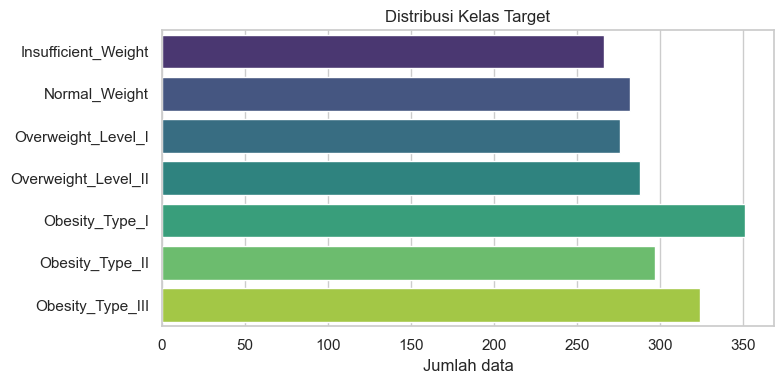

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=df_clean, y="Obesity_Level", order=target_order,
              hue="Obesity_Level", hue_order=target_order, palette="viridis", legend=False, ax=ax)
ax.set_title("Distribusi Kelas Target")
ax.set_xlabel("Jumlah data")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 4.2 Distribusi fitur numerik

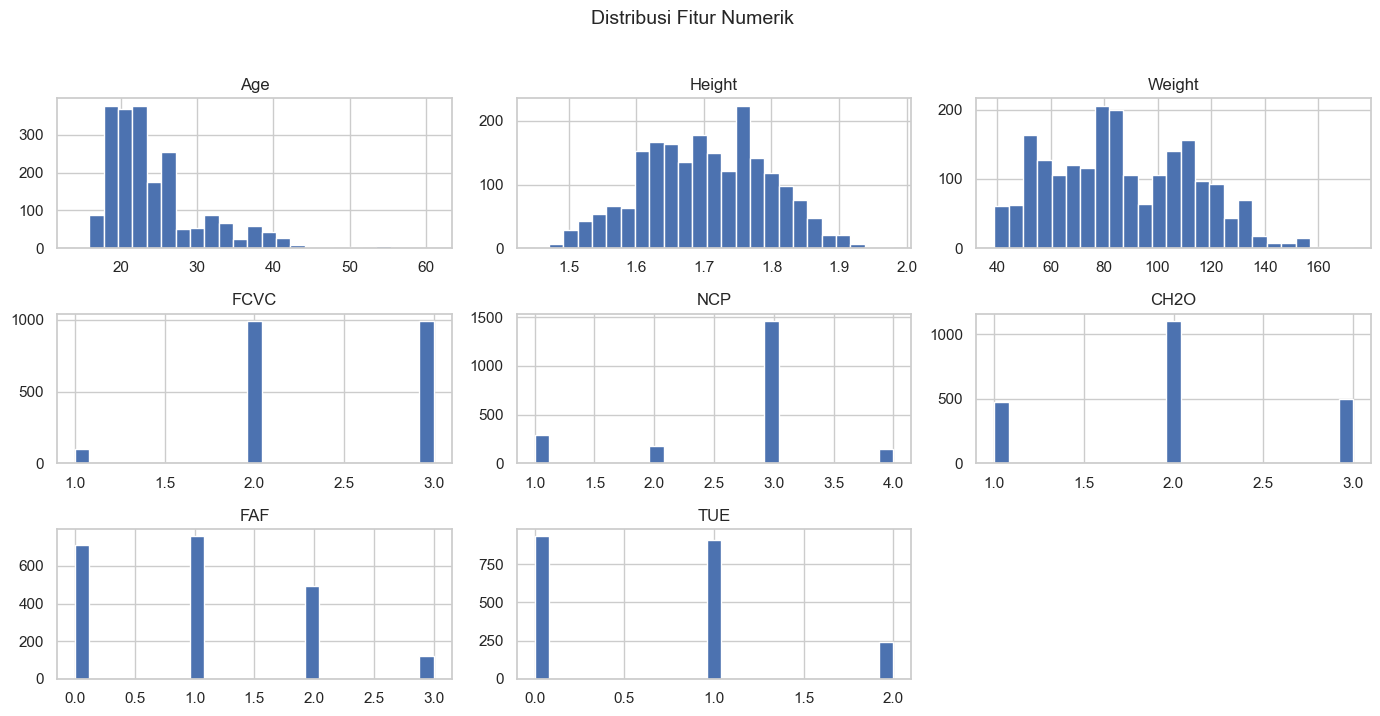

In [14]:
df_clean[num_cols].hist(bins=25, figsize=(14, 7), edgecolor="white", color="#4C72B0")
plt.suptitle("Distribusi Fitur Numerik", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### 4.3 Distribusi fitur kategorikal

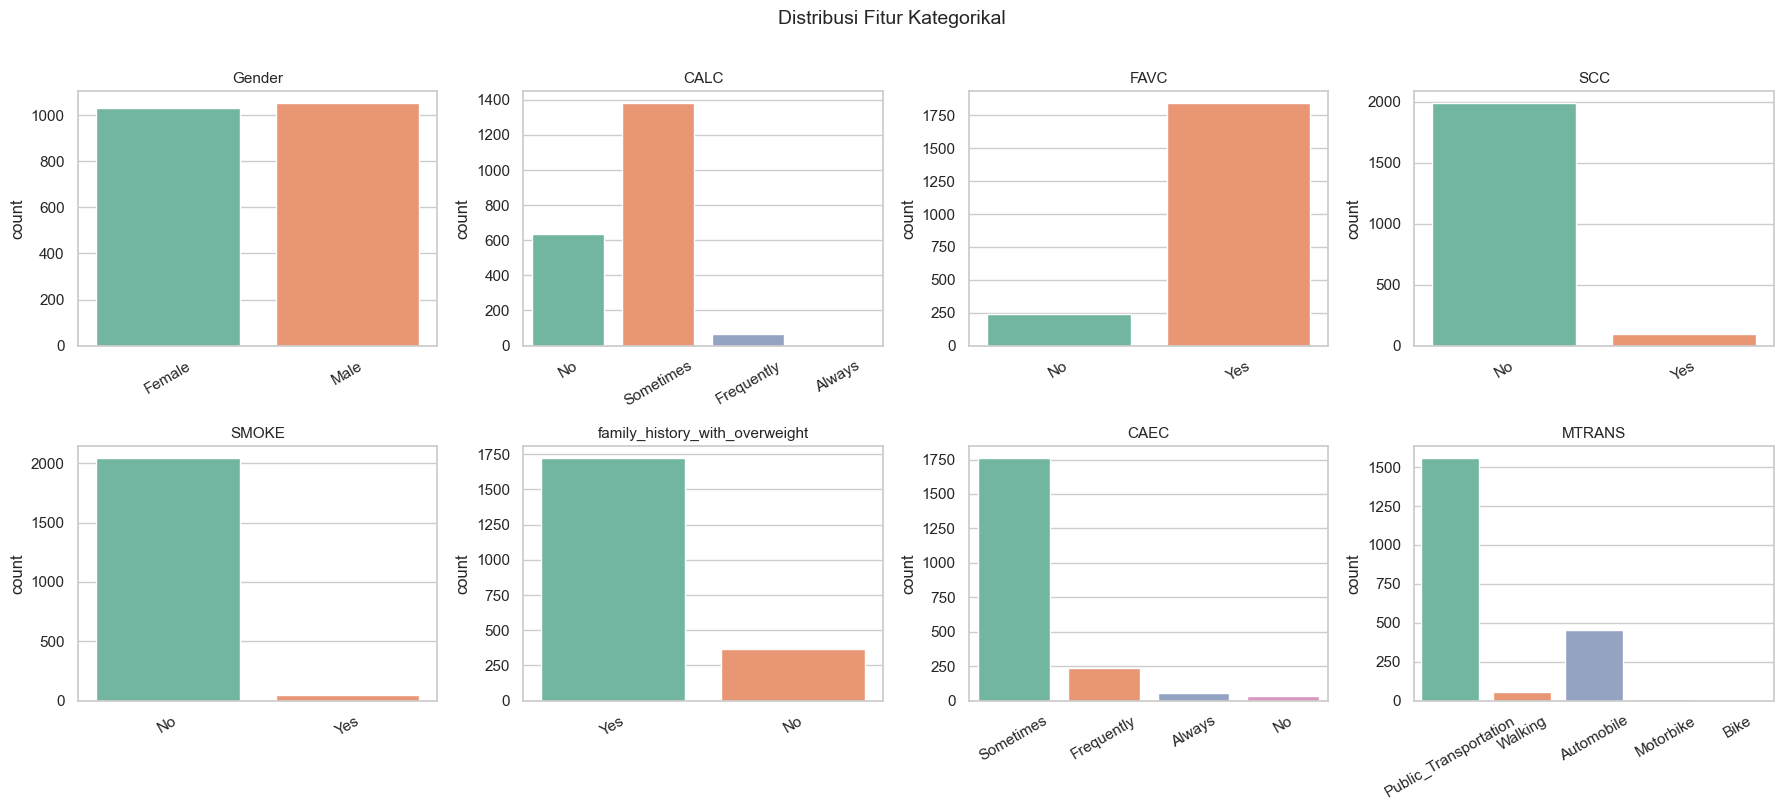

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cat_plot_cols):
    sns.countplot(data=df_clean, x=c, hue=c, palette="Set2", legend=False, ax=ax)
    ax.set_title(c, fontsize=11)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Distribusi Fitur Kategorikal", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

### 4.4 Hubungan fitur dengan kelas target

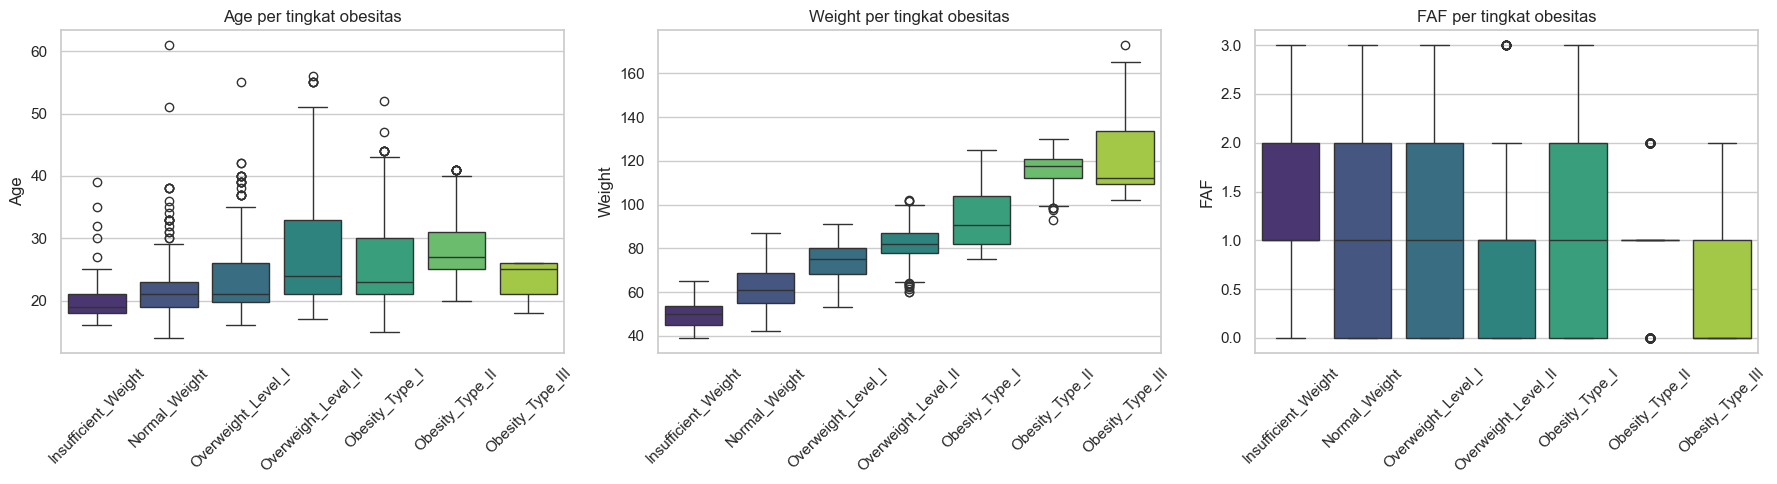

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ["Age", "Weight", "FAF"]):
    sns.boxplot(data=df_clean, x="Obesity_Level", y=c, order=target_order,
                hue="Obesity_Level", hue_order=target_order, palette="viridis", legend=False, ax=ax)
    ax.set_title(f"{c} per tingkat obesitas")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

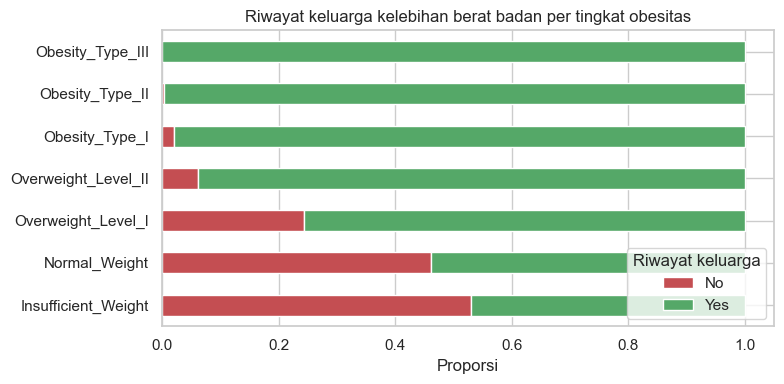

In [17]:
ct = pd.crosstab(df_clean["Obesity_Level"], df_clean["family_history_with_overweight"], normalize="index")
ct = ct.reindex(target_order)

ax = ct.plot(kind="barh", stacked=True, figsize=(8, 4), color=["#C44E52", "#55A868"])
ax.set_title("Riwayat keluarga kelebihan berat badan per tingkat obesitas")
ax.set_xlabel("Proporsi")
ax.set_ylabel("")
ax.legend(title="Riwayat keluarga", loc="lower right")
plt.tight_layout()
plt.show()

## 5. Outlier (metode IQR) — opsional
Aturan IQR: nilai dianggap outlier bila `< Q1 − 1,5×IQR` atau `> Q3 + 1,5×IQR`.
Di sini dicek untuk kolom numerik kontinu yang penting: `Age`, `Height`, `Weight`.

In [18]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in ["Age", "Height", "Weight"]:
    lo, hi = iqr_bounds(df_clean[c])
    n_out = int(((df_clean[c] < lo) | (df_clean[c] > hi)).sum())
    rows.append({"kolom": c, "batas_bawah": round(lo, 2), "batas_atas": round(hi, 2),
                 "jumlah_outlier": n_out, "persen": round(100 * n_out / len(df_clean), 2)})

outlier_table = pd.DataFrame(rows).set_index("kolom")
outlier_table

,batas_bawah,batas_atas,jumlah_outlier,persen
kolom,,,,
Age,11.00,35.00,160,7.68
Height,1.42,1.98,1,0.05
Weight,2.96,171.06,1,0.05


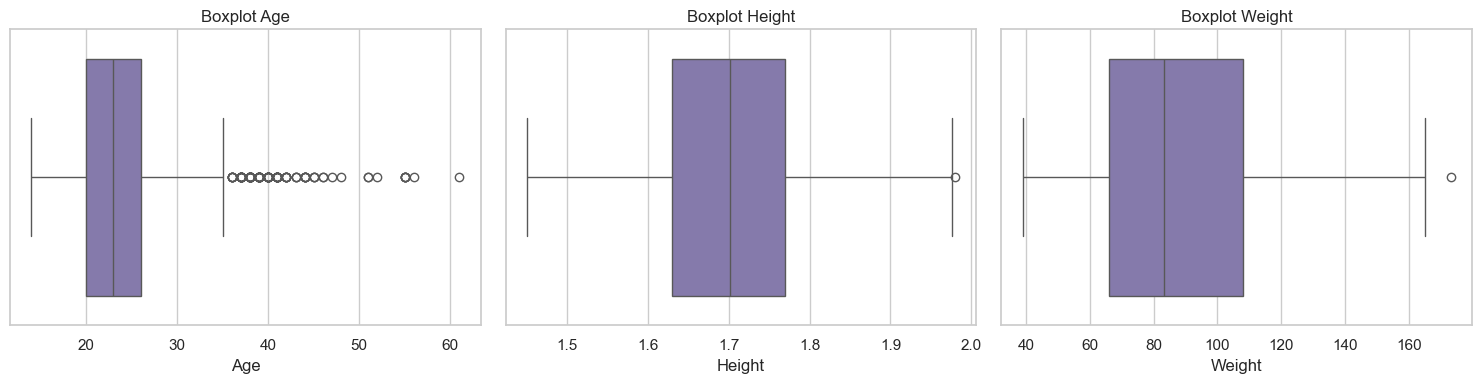

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["Age", "Height", "Weight"]):
    sns.boxplot(x=df_clean[c], color="#8172B3", ax=ax)
    ax.set_title(f"Boxplot {c}")
plt.tight_layout()
plt.show()

**Keputusan penanganan.**
- `Weight` dan `Height`: outlier dipertahankan karena nilainya masuk akal secara medis (orang dengan obesitas berat memang bertubuh besar).
- `Age`: distribusinya condong ke usia muda (banyak responden mahasiswa) sehingga usia tua terdeteksi sebagai outlier.
  Nilai ini dibatasi (*capping/winsorizing*) pada batas IQR agar tidak mendominasi jarak pada KNN.
  Batas dihitung dari **data train saja** (lihat bagian 9) supaya tidak bocor dari data test.

## 6. Ketidakseimbangan Kelas

In [20]:
counts = df_clean["Obesity_Level"].value_counts().reindex(target_order)
summary = pd.DataFrame({"jumlah": counts, "persen": (counts / counts.sum() * 100).round(2)})
display(summary)

ratio = counts.max() / counts.min()
print(f"Rasio kelas terbesar : terkecil = {ratio:.2f} : 1")

,jumlah,persen
Obesity_Level,,
Insufficient_Weight,266,12.76
Normal_Weight,282,13.53
Overweight_Level_I,276,13.24
Overweight_Level_II,288,13.82
Obesity_Type_I,351,16.84
Obesity_Type_II,297,14.25
Obesity_Type_III,324,15.55


Rasio kelas terbesar : terkecil = 1.32 : 1


Rasio kelas sangat dekat dengan 1 : 1, jadi **tidak ada masalah imbalance** yang berarti dan tidak perlu resampling tambahan.
Namun perlu dicatat: keseimbangan ini bukan kondisi alami populasi, melainkan hasil **SMOTE** oleh pembuat dataset.
Itu juga berarti performa model di sini tidak otomatis mewakili kondisi dunia nyata.
Saat membagi data, tetap digunakan `stratify=y` agar proporsi kelas terjaga di train dan test.

## 7. Encoding Fitur Kategorikal & Korelasi
KNN memakai jarak sehingga semua fitur harus berupa angka. Strategi encoding:

| Jenis | Kolom | Teknik |
|---|---|---|
| Biner | `Gender`, `FAVC`, `SCC`, `SMOKE`, `family_history_with_overweight` | 0 / 1 |
| Ordinal (ada urutan) | `CALC`, `CAEC` (No < Sometimes < Frequently < Always) | label berurutan 0–3 |
| Nominal (tanpa urutan) | `MTRANS` | one-hot encoding |
| Target | `Obesity_Level` | label berurutan 0–6 (dari kurus ke obesitas berat) |

In [21]:
df_enc = df_clean.copy()

for c in ["FAVC", "SCC", "SMOKE", "family_history_with_overweight"]:
    df_enc[c] = df_enc[c].map({"No": 0, "Yes": 1})
df_enc["Gender"] = df_enc["Gender"].map({"Female": 0, "Male": 1})

freq_order = {"No": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
for c in ["CALC", "CAEC"]:
    df_enc[c] = df_enc[c].map(freq_order)

target_map = {name: i for i, name in enumerate(target_order)}
df_enc["Obesity_Level"] = df_enc["Obesity_Level"].map(target_map)

df_enc = pd.get_dummies(df_enc, columns=["MTRANS"], dtype=int)

# pastikan tidak ada nilai hilang akibat pemetaan yang salah
assert df_enc.isna().sum().sum() == 0, "Ada nilai kosong setelah encoding, cek ejaan kategori!"
print("Encoding selesai. Ukuran data:", df_enc.shape)
print("\nPemetaan target:", target_map)
df_enc.head()

Encoding selesai. Ukuran data: (2084, 21)

Pemetaan target: {'Insufficient_Weight': 0, 'Normal_Weight': 1, 'Overweight_Level_I': 2, 'Overweight_Level_II': 3, 'Obesity_Type_I': 4, 'Obesity_Type_II': 5, 'Obesity_Type_III': 6}


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,Obesity_Level,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,21,0,1.62,64.0,0,0,2,3,0,0,2,1,0,1,1,1,0,0,0,1,0
1,21,0,1.52,56.0,1,0,3,3,1,1,3,1,3,0,1,1,0,0,0,1,0
2,23,1,1.80,77.0,2,0,2,3,0,0,2,1,2,1,1,1,0,0,0,1,0
3,27,1,1.80,87.0,2,0,3,3,0,0,2,0,2,0,1,2,0,0,0,0,1
4,22,1,1.78,89.8,1,0,2,1,0,0,2,0,0,0,1,3,0,0,0,1,0


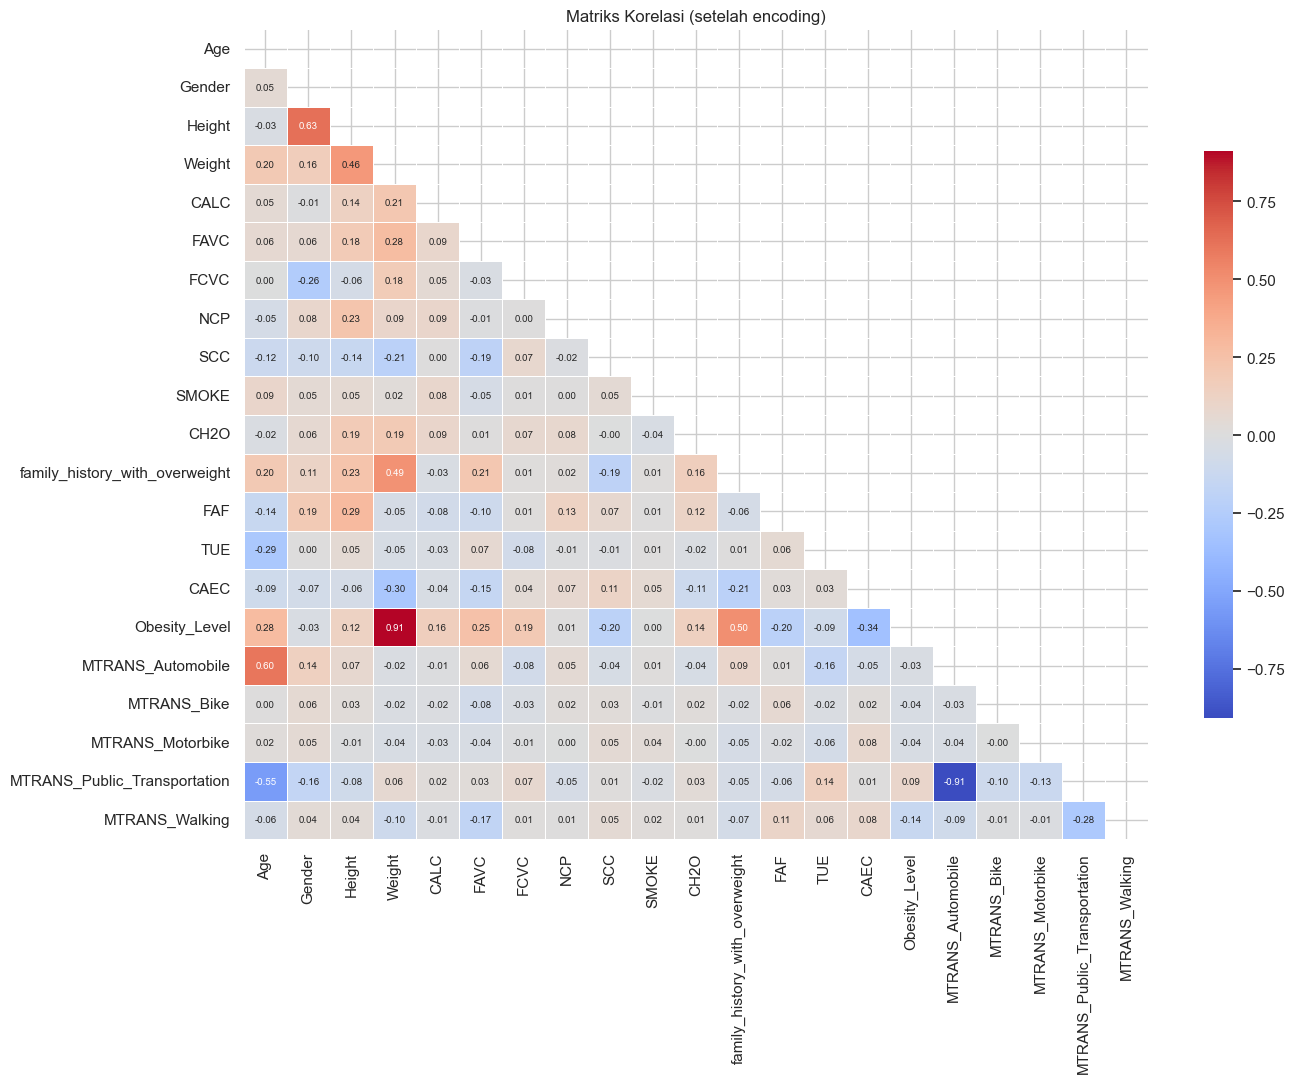

In [22]:
plt.figure(figsize=(14, 11))
corr = df_enc.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.4, cbar_kws={"shrink": 0.7})
plt.title("Matriks Korelasi (setelah encoding)")
plt.tight_layout()
plt.show()

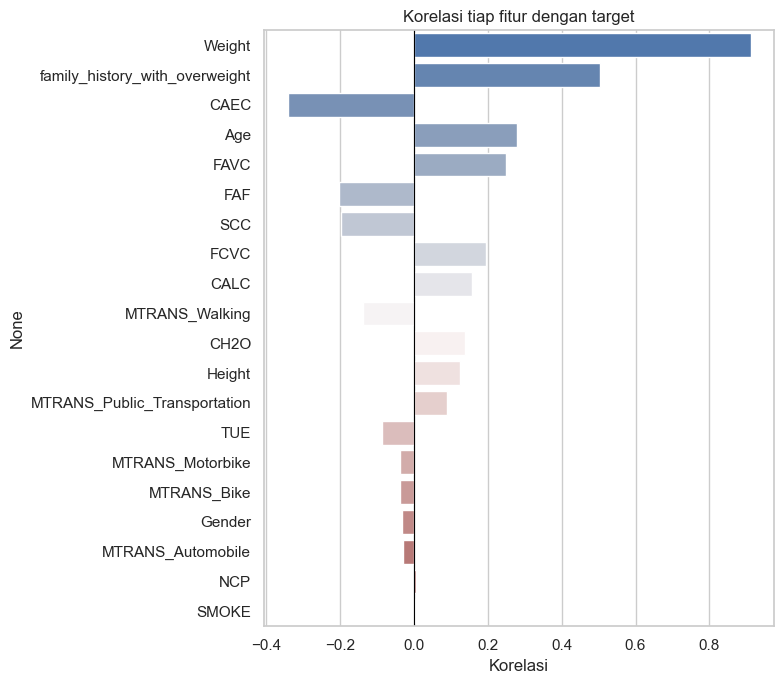

In [23]:
corr_target = corr["Obesity_Level"].drop("Obesity_Level").sort_values(key=abs, ascending=False)

plt.figure(figsize=(8, 7))
sns.barplot(x=corr_target.values, y=corr_target.index, hue=corr_target.index, palette="vlag", legend=False)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Korelasi tiap fitur dengan target")
plt.xlabel("Korelasi")
plt.tight_layout()
plt.show()

## 8. Indikasi Kebocoran Data (Data Leakage)
Kelas target pada dasarnya didefinisikan dari **BMI = Weight / Height²** (kategori WHO).
Artinya `Weight` dan `Height` mengandung informasi yang hampir sama dengan label itu sendiri.
Jika dipakai sebagai fitur, model hanya "menebak dari rumus", bukan belajar dari kebiasaan hidup.
Mari kita buktikan.

In [24]:
bmi = df_enc["Weight"] / df_enc["Height"] ** 2
inv_target = {v: k for k, v in target_map.items()}
tmp = pd.DataFrame({"BMI": bmi, "Level": df_enc["Obesity_Level"].map(inv_target)})

bmi_range = tmp.groupby("Level")["BMI"].agg(["min", "mean", "max"]).reindex(target_order).round(1)
display(bmi_range)

,min,mean,max
Level,,,
Insufficient_Weight,13.0,17.4,19.1
Normal_Weight,18.5,22.0,24.9
Overweight_Level_I,22.8,26.0,28.8
Overweight_Level_II,25.7,28.2,30.4
Obesity_Type_I,29.9,32.3,35.2
Obesity_Type_II,34.0,36.7,39.8
Obesity_Type_III,36.8,42.3,50.8


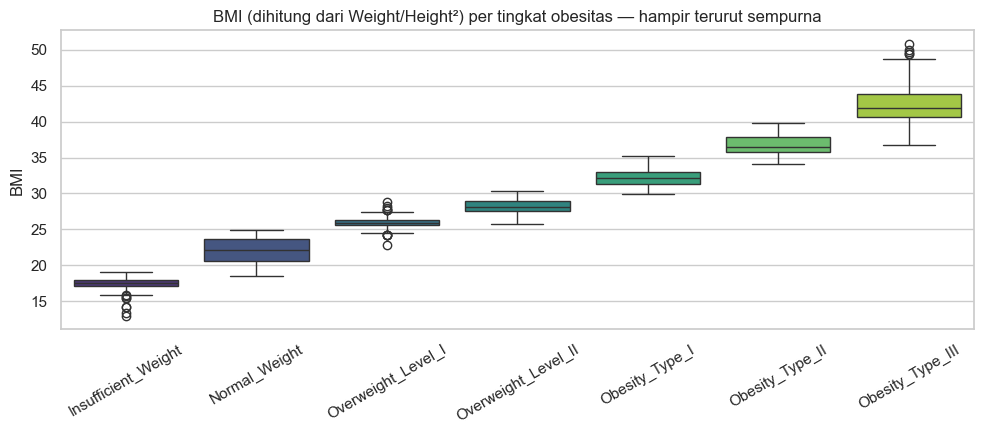

In [25]:
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=tmp, x="Level", y="BMI", order=target_order,
            hue="Level", hue_order=target_order, palette="viridis", legend=False)
plt.title("BMI (dihitung dari Weight/Height²) per tingkat obesitas — hampir terurut sempurna")
plt.xlabel("")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Eksperimen leakage.** Bandingkan akurasi KNN (K=5, 5-fold cross-validation) pada dua skenario:
- **A:** semua fitur (termasuk `Weight` & `Height`)
- **B:** tanpa `Weight` & `Height`

Scaler dimasukkan **di dalam pipeline** sehingga di-*fit* hanya pada data training tiap fold (tidak bocor ke fold validasi).

  File "c:\Users\Rizkya Gusnaldy\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\Rizkya Gusnaldy\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\Rizkya Gusnaldy\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Rizkya Gusnaldy\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1456, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


,Skenario,Akurasi rata-rata,Std
0,A: semua fitur (ada Weight & Height),0.7783,0.0143
1,B: tanpa Weight & Height,0.7255,0.0123


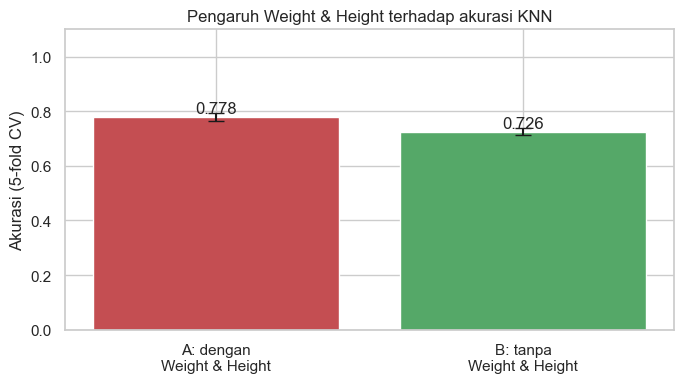

In [26]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

X_all = df_enc.drop(columns=["Obesity_Level"])
y_all = df_enc["Obesity_Level"]
X_noleak = X_all.drop(columns=["Weight", "Height"])

pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

scores_a = cross_val_score(pipe, X_all, y_all, cv=skf, scoring="accuracy")
scores_b = cross_val_score(pipe, X_noleak, y_all, cv=skf, scoring="accuracy")

leak_result = pd.DataFrame({
    "Skenario": ["A: semua fitur (ada Weight & Height)", "B: tanpa Weight & Height"],
    "Akurasi rata-rata": [scores_a.mean(), scores_b.mean()],
    "Std": [scores_a.std(), scores_b.std()],
}).round(4)
display(leak_result)

plt.figure(figsize=(7, 4))
bars = plt.bar(["A: dengan\nWeight & Height", "B: tanpa\nWeight & Height"],
               [scores_a.mean(), scores_b.mean()], yerr=[scores_a.std(), scores_b.std()],
               color=["#C44E52", "#55A868"], capsize=6)
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f"{b.get_height():.3f}", ha="center")
plt.ylim(0, 1.1)
plt.ylabel("Akurasi (5-fold CV)")
plt.title("Pengaruh Weight & Height terhadap akurasi KNN")
plt.tight_layout()
plt.show()

**Kesimpulan leakage.** Selisih akurasi di atas menunjukkan seberapa besar `Weight` dan `Height` "membantu" model hanya karena
keduanya adalah bahan baku label. Untuk tujuan kasus ini (memprediksi dari **kebiasaan hidup**), keduanya **dibuang** dari fitur final.
(Jika tujuannya sekadar menghitung kategori BMI, rumus langsung sudah cukup, tidak perlu machine learning.)

## 9. Split Data, Normalisasi & Standarisasi
Urutan yang benar agar tidak terjadi leakage:
1. Buang fitur yang bocor (`Weight`, `Height`)
2. **Split train/test dulu** (stratified)
3. Hitung batas outlier `Age` dan *fit* scaler **hanya dari data train**, lalu terapkan ke data train dan test

In [27]:
LEAKY_COLS = ["Weight", "Height"]

X = df_enc.drop(columns=["Obesity_Level"] + LEAKY_COLS)
y = df_enc["Obesity_Level"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Jumlah fitur final :", X.shape[1])
print("Data train         :", X_train.shape, "| Data test:", X_test.shape)
print("\nProporsi kelas (train vs test):")
pd.DataFrame({"train": y_train.value_counts(normalize=True).sort_index().round(3),
              "test": y_test.value_counts(normalize=True).sort_index().round(3)})

Jumlah fitur final : 18
Data train         : (1667, 18) | Data test: (417, 18)

Proporsi kelas (train vs test):


,train,test
Obesity_Level,,
0,0.128,0.127
1,0.136,0.134
2,0.133,0.132
3,0.138,0.139
4,0.169,0.168
5,0.142,0.144
6,0.155,0.156


### 9.1 Penanganan outlier `Age` (capping, batas dari data train)

In [28]:
lo, hi = iqr_bounds(X_train["Age"])
print(f"Batas IQR Age (dari train): {lo:.1f} s.d. {hi:.1f}")
print(f"Age maksimum sebelum capping -> train: {X_train['Age'].max()}, test: {X_test['Age'].max()}")

X_train_c = X_train.copy()
X_test_c = X_test.copy()
X_train_c["Age"] = X_train_c["Age"].clip(lower=lo, upper=hi)
X_test_c["Age"] = X_test_c["Age"].clip(lower=lo, upper=hi)

print(f"Age maksimum sesudah capping -> train: {X_train_c['Age'].max()}, test: {X_test_c['Age'].max()}")

Batas IQR Age (dari train): 11.0 s.d. 35.0
Age maksimum sebelum capping -> train: 61, test: 55
Age maksimum sesudah capping -> train: 35, test: 35


### 9.2 Normalisasi (Min-Max) vs Standarisasi (Z-score)
- **Normalisasi (Min-Max):** `x' = (x − min) / (max − min)` → rentang 0–1
- **Standarisasi (Z-score):** `x' = (x − mean) / std` → rata-rata 0, simpangan baku 1

Kolom yang diskalakan adalah kolom non-biner: `Age`, `FCVC`, `NCP`, `CH2O`, `FAF`, `TUE`, `CALC`, `CAEC`.
Kolom biner / one-hot sudah berada pada rentang 0–1 sehingga dibiarkan.

In [29]:
scale_cols = ["Age", "FCVC", "NCP", "CH2O", "FAF", "TUE", "CALC", "CAEC"]

minmax = MinMaxScaler().fit(X_train_c[scale_cols])      # fit HANYA pada train
standard = StandardScaler().fit(X_train_c[scale_cols])  # fit HANYA pada train

X_train_mm, X_test_mm = X_train_c.copy(), X_test_c.copy()
X_train_std, X_test_std = X_train_c.copy(), X_test_c.copy()

X_train_mm[scale_cols] = minmax.transform(X_train_c[scale_cols])
X_test_mm[scale_cols] = minmax.transform(X_test_c[scale_cols])
X_train_std[scale_cols] = standard.transform(X_train_c[scale_cols])
X_test_std[scale_cols] = standard.transform(X_test_c[scale_cols])

stats = pd.concat({
    "Asli": X_train_c[scale_cols].agg(["min", "max", "mean", "std"]).T,
    "Min-Max": X_train_mm[scale_cols].agg(["min", "max", "mean", "std"]).T,
    "Z-score": X_train_std[scale_cols].agg(["min", "max", "mean", "std"]).T,
}, axis=1).round(2)
stats

Asli                    Min-Max                  Z-score                
       min   max   mean   std     min  max  mean   std     min   max mean  std
Age   15.0  35.0  23.97  5.26     0.0  1.0  0.45  0.26   -1.71  2.10 -0.0  1.0
FCVC   1.0   3.0   2.42  0.58     0.0  1.0  0.71  0.29   -2.44  0.99  0.0  1.0
NCP    1.0   4.0   2.69  0.80     0.0  1.0  0.56  0.27   -2.11  1.62  0.0  1.0
CH2O   1.0   3.0   2.00  0.69     0.0  1.0  0.50  0.34   -1.47  1.45  0.0  1.0
FAF    0.0   3.0   0.99  0.89     0.0  1.0  0.33  0.30   -1.11  2.25 -0.0  1.0
TUE    0.0   2.0   0.66  0.67     0.0  1.0  0.33  0.34   -0.98  1.99 -0.0  1.0
CALC   0.0   3.0   0.73  0.52     0.0  1.0  0.24  0.17   -1.40  4.34 -0.0  1.0
CAEC   0.0   3.0   1.15  0.46     0.0  1.0  0.38  0.15   -2.48  3.99  0.0  1.0

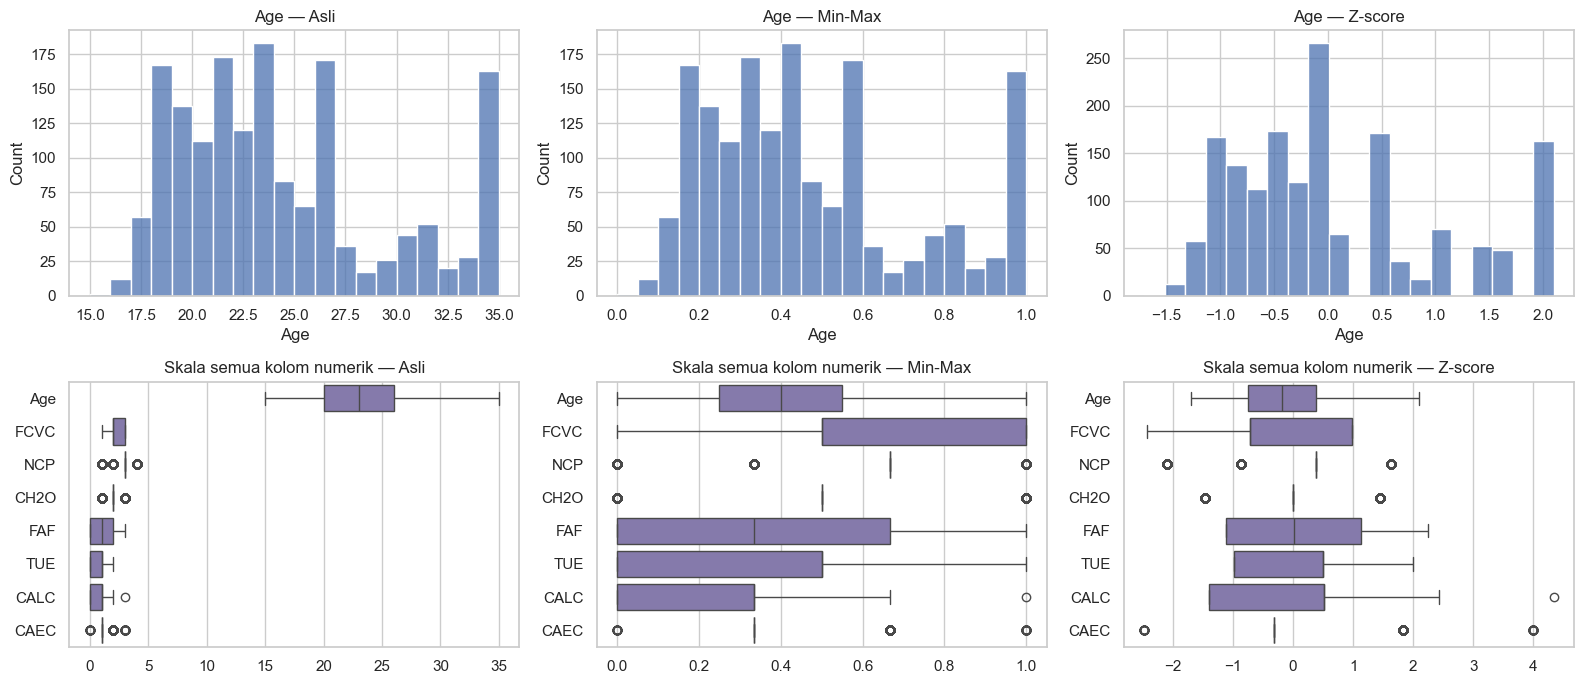

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for j, (title, data) in enumerate([("Asli", X_train_c), ("Min-Max", X_train_mm), ("Z-score", X_train_std)]):
    sns.histplot(data["Age"], bins=20, color="#4C72B0", ax=axes[0, j])
    axes[0, j].set_title(f"Age — {title}")
    sns.boxplot(data=data[scale_cols], orient="h", color="#8172B3", ax=axes[1, j])
    axes[1, j].set_title(f"Skala semua kolom numerik — {title}")
plt.tight_layout()
plt.show()

Pada data asli, rentang `Age` (≈15–35 setelah capping) jauh lebih besar dibanding `FCVC` (1–3) atau `TUE` (0–2),
sehingga pada jarak Euclidean `Age` akan mendominasi. Setelah diskalakan, semua kolom memiliki skala sebanding.

### 9.3 Hasil pra-pemrosesan: 5 data teratas & 5 data terbawah
**(a) Data setelah dibersihkan & di-encode (sebelum split dan scaling)**

In [31]:
display_df = df_enc.drop(columns=LEAKY_COLS)
print("Ukuran:", display_df.shape)
print("\n=== 5 DATA TERATAS ===")
display(display_df.head(5))
print("=== 5 DATA TERBAWAH ===")
display(display_df.tail(5))

Ukuran: (2084, 19)

=== 5 DATA TERATAS ===


,Age,Gender,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,Obesity_Level,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,21,0,0,0,2,3,0,0,2,1,0,1,1,1,0,0,0,1,0
1,21,0,1,0,3,3,1,1,3,1,3,0,1,1,0,0,0,1,0
2,23,1,2,0,2,3,0,0,2,1,2,1,1,1,0,0,0,1,0
3,27,1,2,0,3,3,0,0,2,0,2,0,1,2,0,0,0,0,1
4,22,1,1,0,2,1,0,0,2,0,0,0,1,3,0,0,0,1,0


=== 5 DATA TERBAWAH ===


,Age,Gender,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,Obesity_Level,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
2079,21,0,1,1,3,3,0,0,2,1,2,1,1,6,0,0,0,1,0
2080,22,0,1,1,3,3,0,0,2,1,1,1,1,6,0,0,0,1,0
2081,23,0,1,1,3,3,0,0,2,1,1,1,1,6,0,0,0,1,0
2082,24,0,1,1,3,3,0,0,3,1,1,1,1,6,0,0,0,1,0
2083,24,0,1,1,3,3,0,0,3,1,1,1,1,6,0,0,0,1,0


**(b) Data train final (setelah capping outlier + standarisasi), lengkap dengan target**

In [32]:
train_final = X_train_std.copy()
train_final["Obesity_Level"] = y_train

print("Ukuran data train final:", train_final.shape)
print("\n=== 5 DATA TERATAS ===")
display(train_final.head(5).round(3))
print("=== 5 DATA TERBAWAH ===")
display(train_final.tail(5).round(3))

Ukuran data train final: (1667, 19)

=== 5 DATA TERATAS ===


,Age,Gender,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking,Obesity_Level
81,1.148,1,0.516,1,-0.724,0.380,0,0,-0.007,1,-1.111,-0.983,1.834,0,0,0,1,0,3
1603,1.148,1,-1.395,1,0.988,-0.864,0,0,-1.467,1,0.011,0.504,-0.321,0,0,0,1,0,5
355,2.099,0,0.516,0,0.988,0.380,0,0,-0.007,1,0.011,-0.983,-0.321,1,0,0,0,0,2
225,-0.564,0,0.516,1,0.988,-2.108,0,1,1.453,1,-1.111,-0.983,-0.321,0,0,0,1,0,1
543,-1.516,1,0.516,1,-0.724,-0.864,0,0,1.453,0,0.011,-0.983,-0.321,0,0,0,1,0,0


=== 5 DATA TERBAWAH ===


,Age,Gender,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking,Obesity_Level
427,-0.945,1,2.427,1,-0.724,1.624,0,0,-0.007,0,2.253,0.504,1.834,1,0,0,0,0,1
902,-0.755,1,0.516,1,0.988,0.380,0,0,1.453,1,2.253,-0.983,-0.321,0,0,0,1,0,2
1621,1.338,1,0.516,1,0.988,0.380,0,0,-0.007,1,0.011,0.504,-0.321,1,0,0,0,0,5
72,0.006,0,-1.395,0,-0.724,0.380,1,0,1.453,1,0.011,-0.983,-0.321,0,0,0,1,0,1
1343,-1.135,0,-1.395,1,0.988,0.380,0,0,-1.467,1,0.011,0.504,-0.321,0,0,0,1,0,4


## 10. Model KNN & Evaluasi
### 10.1 Seberapa penting scaling untuk KNN?
Perbandingan akurasi (5-fold CV pada data train) untuk K=5: tanpa scaling, Min-Max, dan Z-score.

,akurasi_rata2,std
Tanpa scaling,0.7109,0.0145
Min-Max,0.6905,0.0208
Z-score,0.6857,0.0104


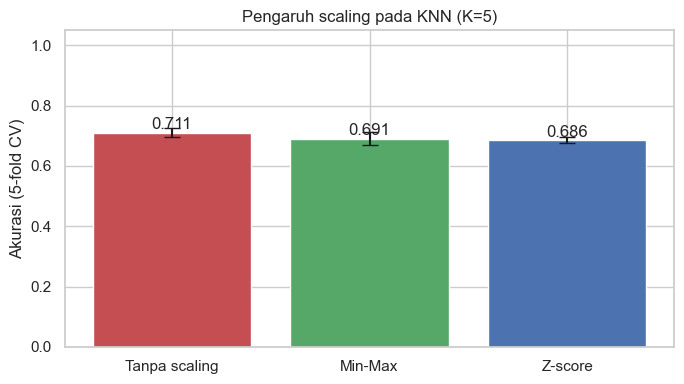

In [33]:
def make_knn(scaler=None, k=5):
    knn = KNeighborsClassifier(n_neighbors=k)
    if scaler is None:
        return knn
    ct = ColumnTransformer([("scale", scaler, scale_cols)], remainder="passthrough")
    return make_pipeline(ct, knn)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cmp = {}
for name, sc in [("Tanpa scaling", None), ("Min-Max", MinMaxScaler()), ("Z-score", StandardScaler())]:
    s = cross_val_score(make_knn(sc, 5), X_train_c, y_train, cv=skf, scoring="accuracy")
    cmp[name] = (s.mean(), s.std())

cmp_df = pd.DataFrame(cmp, index=["akurasi_rata2", "std"]).T.round(4)
display(cmp_df)

plt.figure(figsize=(7, 4))
bars = plt.bar(cmp_df.index, cmp_df["akurasi_rata2"], yerr=cmp_df["std"], color=["#C44E52", "#55A868", "#4C72B0"], capsize=6)
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012, f"{b.get_height():.3f}", ha="center")
plt.ylim(0, 1.05)
plt.ylabel("Akurasi (5-fold CV)")
plt.title("Pengaruh scaling pada KNN (K=5)")
plt.tight_layout()
plt.show()

### 10.2 Mencari nilai K terbaik
K terlalu kecil → sensitif terhadap noise; K terlalu besar → batas keputusan terlalu halus.
Dicoba K = 1 sampai 30 dengan Z-score + 5-fold CV pada data train (data test belum disentuh).

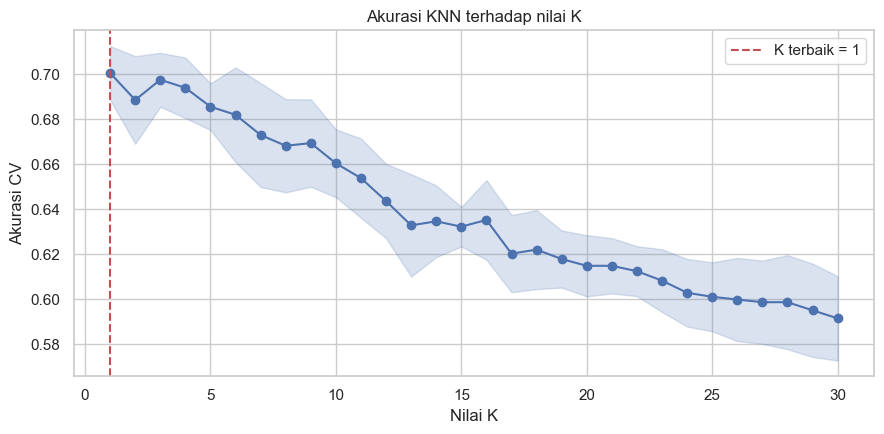

K terbaik: 1 dengan akurasi CV 0.7007


In [34]:
k_values = range(1, 31)
cv_mean, cv_std = [], []
for k in k_values:
    s = cross_val_score(make_knn(StandardScaler(), k), X_train_c, y_train, cv=skf, scoring="accuracy")
    cv_mean.append(s.mean())
    cv_std.append(s.std())

cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)
best_k = list(k_values)[int(cv_mean.argmax())]

plt.figure(figsize=(9, 4.5))
plt.plot(list(k_values), cv_mean, marker="o", color="#4C72B0")
plt.fill_between(list(k_values), cv_mean - cv_std, cv_mean + cv_std, alpha=0.2, color="#4C72B0")
plt.axvline(best_k, color="#C44E52", linestyle="--", label=f"K terbaik = {best_k}")
plt.xlabel("Nilai K")
plt.ylabel("Akurasi CV")
plt.title("Akurasi KNN terhadap nilai K")
plt.legend()
plt.tight_layout()
plt.show()

print(f"K terbaik: {best_k} dengan akurasi CV {cv_mean.max():.4f}")

**Catatan membaca grafik.** Jika K terbaik jatuh pada nilai sangat kecil (mis. K=1), itu patut dicurigai, bukan dirayakan.
Sebagian besar data ini adalah titik sintetis hasil SMOTE, yaitu interpolasi antara dua data asli. Akibatnya sebuah titik sintetis
sering punya "kembaran dekat" di data lain; bila kembaran itu jatuh di train dan titiknya di test (atau di fold validasi),
KNN dengan K kecil bisa menebak benar hanya dengan menyalin tetangga terdekat. Ini bentuk leakage halus yang berasal dari cara dataset dibuat.
Karena itu akurasi di sini cenderung optimistis, dan K yang sedikit lebih besar (mis. K=5–10) biasanya lebih aman secara generalisasi
walau akurasi CV-nya mirip.

### 10.3 Evaluasi akhir pada data test
Model final dilatih pada seluruh data train, lalu diuji **sekali** pada data test.

In [35]:
final_model = make_knn(StandardScaler(), best_k).fit(X_train_c, y_train)
y_pred = final_model.predict(X_test_c)

test_acc = accuracy_score(y_test, y_pred)
print(f"Akurasi pada data test (K={best_k}): {test_acc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=target_order, digits=3))

Akurasi pada data test (K=1): 0.6906

                     precision    recall  f1-score   support

Insufficient_Weight      0.700     0.792     0.743        53
      Normal_Weight      0.500     0.339     0.404        56
 Overweight_Level_I      0.571     0.655     0.610        55
Overweight_Level_II      0.612     0.517     0.561        58
     Obesity_Type_I      0.618     0.671     0.644        70
    Obesity_Type_II      0.836     0.850     0.843        60
   Obesity_Type_III      0.900     0.969     0.933        65

           accuracy                          0.691       417
          macro avg      0.677     0.685     0.677       417
       weighted avg      0.681     0.691     0.682       417



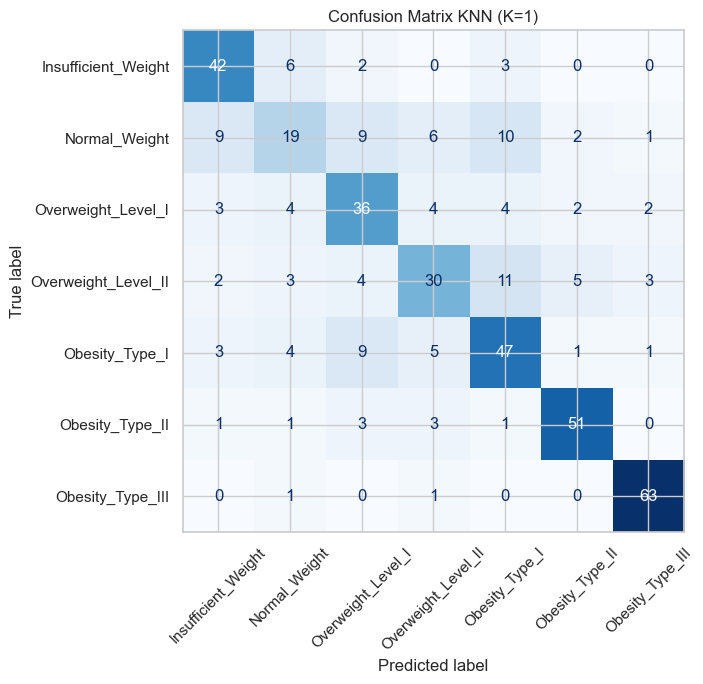

In [36]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=target_order).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Confusion Matrix KNN (K={best_k})")
plt.tight_layout()
plt.show()

## 11. Ringkasan & Kesimpulan
Ringkasan angka di bawah dihasilkan otomatis dari hasil eksekusi notebook ini.

In [37]:
print("RINGKASAN PRA-PEMROSESAN")
print("-" * 60)
print(f"Data awal                      : {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
print(f"Duplikat dihapus               : {before - len(df_clean)} baris")
print(f"Missing value                  : {int(df_raw.isna().sum().sum())}")
print(f"Data setelah dibersihkan       : {len(df_clean)} baris")
print(f"Fitur final (tanpa leakage)    : {X.shape[1]} fitur  (dibuang: {', '.join(LEAKY_COLS)})")
print(f"Rasio kelas terbesar:terkecil  : {ratio:.2f} : 1")
print(f"Akurasi KNN dengan leakage (CV): {scores_a.mean():.3f}")
print(f"Akurasi KNN tanpa leakage (CV) : {scores_b.mean():.3f}")
print(f"K terbaik                      : {best_k}")
print(f"Akurasi data test              : {test_acc:.3f}")

RINGKASAN PRA-PEMROSESAN
------------------------------------------------------------
Data awal                      : 2111 baris, 17 kolom
Duplikat dihapus               : 27 baris
Missing value                  : 0
Data setelah dibersihkan       : 2084 baris
Fitur final (tanpa leakage)    : 18 fitur  (dibuang: Weight, Height)
Rasio kelas terbesar:terkecil  : 1.32 : 1
Akurasi KNN dengan leakage (CV): 0.778
Akurasi KNN tanpa leakage (CV) : 0.726
K terbaik                      : 1
Akurasi data test              : 0.691


**Poin penting**
1. **Tipe kolom:** skor survei dan usia yang berdesimal akibat SMOTE dibulatkan menjadi bilangan bulat.
2. **Missing values:** tidak ada.
3. **Duplikasi:** duplikat dihapus sebelum split agar baris yang sama tidak muncul di train dan test.
4. **Kategori:** kapitalisasi diseragamkan; biner → 0/1, ordinal → label berurutan, nominal (`MTRANS`) → one-hot.
5. **Normalisasi/standarisasi:** wajib untuk KNN karena berbasis jarak; scaler hanya di-*fit* pada data train.
6. **Outlier:** `Age` di-*capping* dengan batas IQR dari data train; `Weight`/`Height` dipertahankan (masuk akal secara medis).
7. **Class imbalance:** hampir seimbang, tetapi karena hasil SMOTE; split memakai `stratify`.
8. **Leakage:** `Weight` dan `Height` adalah bahan baku BMI yang mendefinisikan label, sehingga dibuang dari fitur.
9. **Keterbatasan:** sebagian besar data sintetis, sehingga hasil tidak serta-merta mewakili populasi nyata.